<a href="https://colab.research.google.com/github/AbigailWolfmeyer/ores5160-2026/blob/main/week11/week11_Assignment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


Q1. Reading the CSV File (pandas + csv)

	1.	Use the csv module to open and print the first 5 rows of est2018-pop-res.csv.

	2.	Then use pandas.read_csv() to load the same file into a DataFrame.

	•	Display the shape (rows × columns).

	•	Print the list of column names.

	3.	Which column represents total population? Display the top 5 most populous states


In [1]:
from google.colab import files

uploaded = files.upload()

Saving est2018-pop-res.csv to est2018-pop-res.csv


In [2]:
import os

print(os.listdir())

['.config', 'est2018-pop-res.csv', 'sample_data']


In [3]:
# 1.1

import csv

with open("est2018-pop-res.csv", "r") as file:
    reader = csv.reader(file)

    for i, row in enumerate(reader):
        if i < 5:
            print(row)

['SUMLEV', 'REGION', 'DIVISION', 'STATE', 'NAME', 'POPESTIMATE2018', 'POPEST18PLUS2018', 'PCNT_POPEST18PLUS']
['010', '0', '0', '00', 'United States', '327167434', '253768092', '77.6']
['040', '3', '6', '01', 'Alabama', '4887871', '3798031', '77.7']
['040', '4', '9', '02', 'Alaska', '737438', '553622', '75.1']
['040', '4', '8', '04', 'Arizona', '7171646', '5528989', '77.1']


In [4]:
# 1.2

import pandas as pd

df = pd.read_csv("est2018-pop-res.csv")

print("Shape:", df.shape)
print("Column names:", df.columns.tolist())

Shape: (53, 8)
Column names: ['SUMLEV', 'REGION', 'DIVISION', 'STATE', 'NAME', 'POPESTIMATE2018', 'POPEST18PLUS2018', 'PCNT_POPEST18PLUS']


The column that represents the total population is POPESTIMATE2018.

In [5]:
# 1.3

states = df[df["SUMLEV"] == 40]

top5 = states.nlargest(5, "POPESTIMATE2018")

print(top5[["NAME", "POPESTIMATE2018"]])

            NAME  POPESTIMATE2018
5     California         39557045
44         Texas         28701845
10       Florida         21299325
33      New York         19542209
39  Pennsylvania         12807060


Q2. Basic Statistical Analysis (pandas)

	1.	Compute the average population across all states.

	2.	Find which region has the highest total population.

	3.	Plot a bar chart showing the population by region (use matplotlib)

In [6]:
# 2.1

average_population = states["POPESTIMATE2018"].mean()

print("Average state population:", average_population)

Average state population: 6353126.673076923


In [7]:
# 2.2

region_population = states.groupby("REGION")["POPESTIMATE2018"].sum()

print(region_population)

print("Region with the highest population:", region_population.idxmax())

REGION
1     56111079
2     68308744
3    124753948
4     77993663
X      3195153
Name: POPESTIMATE2018, dtype: int64
Region with the highest population: 3


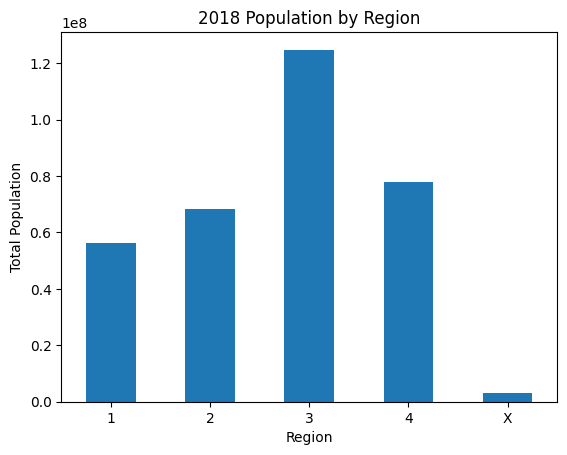

In [8]:
# 2.3

import matplotlib.pyplot as plt

region_population.plot(kind="bar")

plt.title("2018 Population by Region")
plt.xlabel("Region")
plt.ylabel("Total Population")
plt.xticks(rotation=0)
plt.show()

Q3. Parsing the JSON File (FHIR structure)

Using json module:

	1.	Load patient.json into a Python dictionary.

	2.	Extract and print:

	•	Patient’s full official name

	•	Gender and birth date

	•	Current address (city, state, postal code)
  
	3.	Count how many phone numbers the patient has, and list their types (e.g., work, mobile, home).

In [9]:
from google.colab import files

uploaded = files.upload()

Saving patient.json to patient.json


In [10]:
# 3.1

import json

with open("patient.json", "r") as file:
    patient = json.load(file)

print(type(patient))

<class 'dict'>


In [11]:
# 3.2

# Patient's full official name
official_name = next(
    name for name in patient["name"]
    if name["use"] == "official"
)

first_name = " ".join(official_name["given"])
last_name = official_name["family"]

print("Official name:", first_name, last_name)

# Gender and birth date
print("Gender:", patient["gender"])
print("Birth date:", patient["birthDate"])

# Current address
current_address = patient["address"][0]

print("City:", current_address["city"])
print("State:", current_address["state"])
print("Postal code:", current_address["postalCode"])

Official name: Peter James Chalmers
Gender: male
Birth date: 1974-12-25
City: PleasantVille
State: Vic
Postal code: 3999


In [12]:
# 3.3

# Identify phone numbers
phone_numbers = [
    contact for contact in patient["telecom"]
    if contact.get("system") == "phone"
]

# Count phone numbers
print("Number of phone numbers:", len(phone_numbers))

# Print phone number types
for contact in phone_numbers:
    print("Type:", contact["use"])

Number of phone numbers: 3
Type: work
Type: mobile
Type: old
